In [46]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("superstore.csv")
print("Dataset loaded successfully!")
print(df.head)


Dataset loaded successfully!
<bound method NDFrame.head of       Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
0          1  CA-2016-152156  11-08-2016  11-11-2016    Second Class   
1          2  CA-2016-152156  11-08-2016  11-11-2016    Second Class   
2          3  CA-2016-138688  06-12-2016   6/16/2016    Second Class   
3          4  US-2015-108966  10-11-2015  10/18/2015  Standard Class   
4          5  US-2015-108966  10-11-2015  10/18/2015  Standard Class   
...      ...             ...         ...         ...             ...   
9989    9990  CA-2014-110422   1/21/2014   1/23/2014    Second Class   
9990    9991  CA-2017-121258   2/26/2017  03-03-2017  Standard Class   
9991    9992  CA-2017-121258   2/26/2017  03-03-2017  Standard Class   
9992    9993  CA-2017-121258   2/26/2017  03-03-2017  Standard Class   
9993    9994  CA-2017-119914  05-04-2017  05-09-2017    Second Class   

     Customer ID     Customer Name    Segment        Country             Cit

In [3]:
print("Number of rows: ",df.shape[0])
print("Number of columns: ",df.shape[1])
print("\nColumn names: ")
print(df.columns.tolist())
print("\nMissing values: ")
print(df.isnull().sum())

Number of rows:  9994
Number of columns:  21

Column names: 
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing values: 
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [4]:
print(df.dtypes)

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [5]:
print("Duplicate rows: ",df.duplicated().sum())

Duplicate rows:  0


# Proper Date format

In [6]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="mixed")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="mixed")
print("Date columns converted successfully!")
print(df[["Order Date","Ship Date"]].dtypes)

Date columns converted successfully!
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


# Calculate key business metrices


In [7]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_order = df["Order ID"].nunique()

print("Total Sales: ", round(total_sales, 2))
print("Total Profit: ", round(total_profit, 2))
print("Total Quantity sold: ", total_quantity)
print("Total Orders: ", total_order)

Total Sales:  2297200.86
Total Profit:  286397.02
Total Quantity sold:  37873
Total Orders:  5009


# Sales and Profit by category


In [8]:
category_analysis = df.groupby("Category")[["Sales", "Profit"]].sum()
print(category_analysis)

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


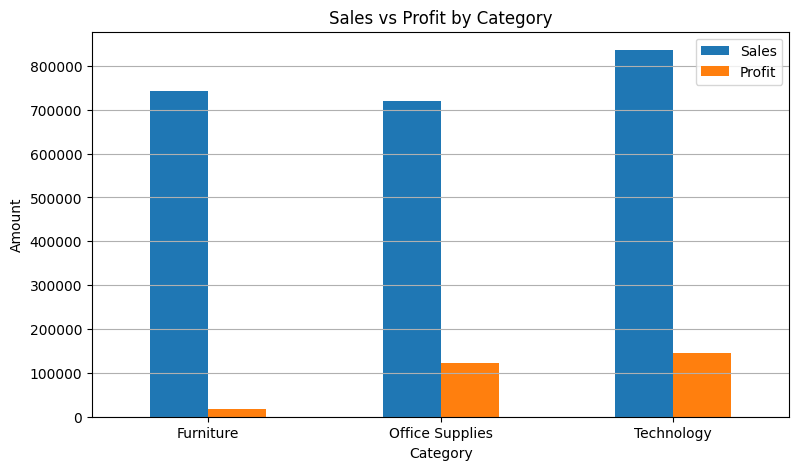

In [9]:
category_analysis.plot(kind="bar", figsize=(9,5))
plt.title("Sales vs Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# Sort categories by sales


In [10]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(category_sales)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


# Sales and profit by region

In [11]:
region_analysis = df.groupby("Region")[["Sales", "Profit"]].sum()
print(region_analysis)

               Sales       Profit
Region                           
Central  501239.8908   39706.3625
East     678781.2400   91522.7800
South    391721.9050   46749.4303
West     725457.8245  108418.4489


# sort region by sales

In [12]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(region_sales)

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


# Top 10 products by sales

In [13]:
top_product = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
print(top_product)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


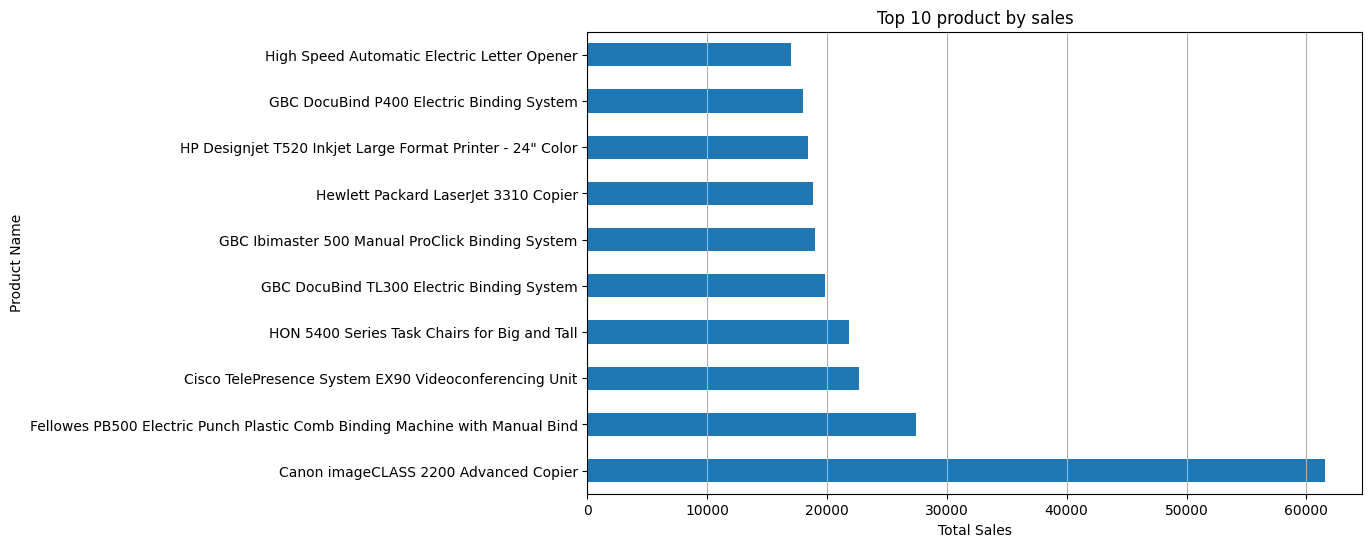

In [14]:
top_product.plot(kind="barh", figsize=(10,6))
plt.title("Top 10 product by sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.grid(axis="x")
plt.show()

# Top 10 product by profit


In [15]:
top_profit_product = df.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(10)
print(top_profit_product)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64


# Monthly sales summary

In [16]:
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
print(monthly_sales)

Order Date
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


# Sales trend chart

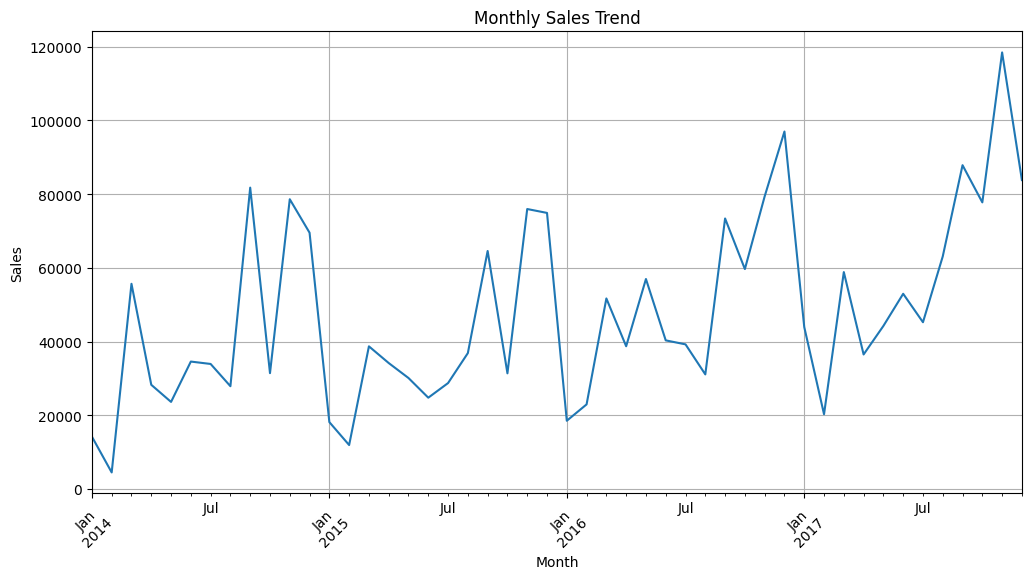

In [17]:
monthly_sales.plot(kind="line", figsize=(12, 6))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# Monthly Profit summary

In [18]:
monthly_profit = (df.groupby(df["Order Date"].dt.to_period("M"))["Profit"].sum())
print(monthly_profit)

Order Date
2014-01     2450.1907
2014-02      862.3084
2014-03      498.7299
2014-04     3488.8352
2014-05     2738.7096
2014-06     4976.5244
2014-07     -841.4826
2014-08     5318.1050
2014-09     8328.0994
2014-10     3448.2573
2014-11     9292.1269
2014-12     8983.5699
2015-01    -3281.0070
2015-02     2813.8508
2015-03     9732.0978
2015-04     4187.4962
2015-05     4667.8690
2015-06     3335.5572
2015-07     3288.6483
2015-08     5355.8084
2015-09     8209.1627
2015-10     2817.3660
2015-11    12474.7884
2015-12     8016.9659
2016-01     2824.8233
2016-02     5004.5795
2016-03     3611.9680
2016-04     2977.8149
2016-05     8662.1464
2016-06     4750.3781
2016-07     4432.8779
2016-08     2062.0693
2016-09     9328.6576
2016-10    16243.1425
2016-11     4011.4075
2016-12    17885.3093
2017-01     7140.4391
2017-02     1613.8720
2017-03    14751.8915
2017-04      933.2900
2017-05     6342.5828
2017-06     8223.3357
2017-07     6952.6212
2017-08     9040.9557
2017-09    10991.5556

# Profit Trend Chart

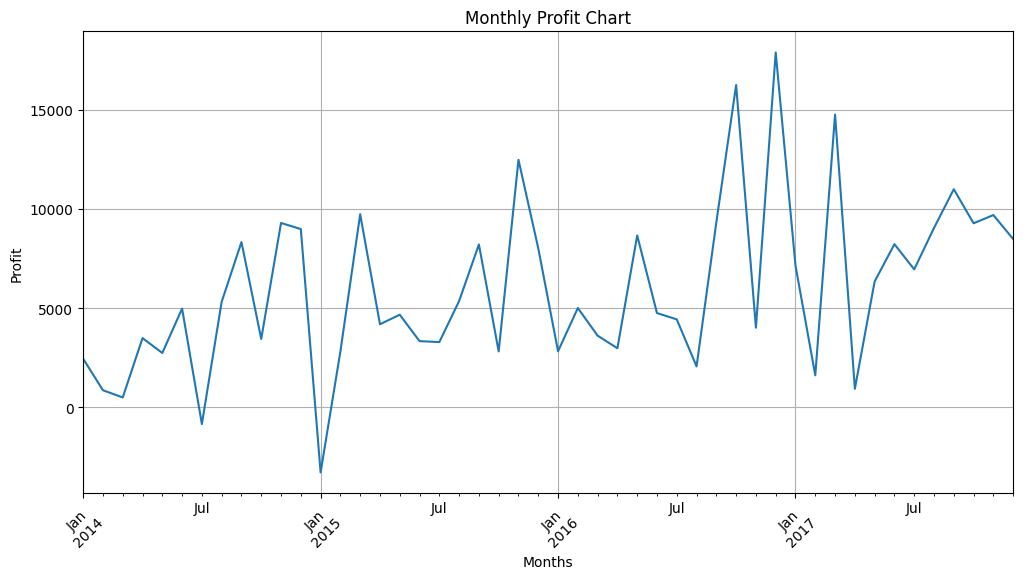

In [19]:
monthly_profit.plot(kind="line", figsize=(12, 6))
plt.title("Monthly Profit Chart")
plt.xlabel("Months")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# Sales by category

In [20]:
category_sales = df.groupby("Category")["Sales"].sum()
print(category_sales)

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


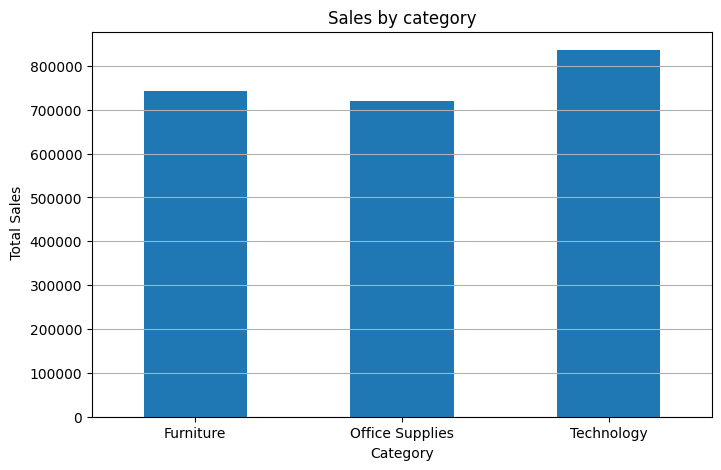

In [21]:
category_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Sales by category")
plt.xlabel("Category")
plt.ylabel(" Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# Sales by region

In [22]:
region_sales = df.groupby("Region")["Sales"].sum()
print(region_sales)

Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64


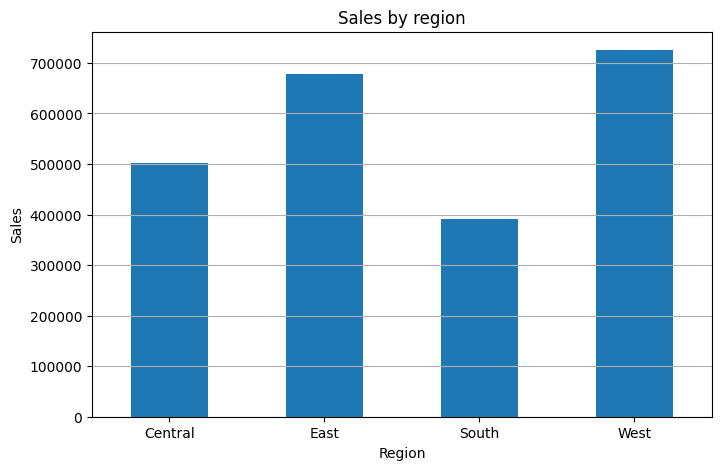

In [23]:
region_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Sales by region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# Discount vs Profit Analysis

In [24]:
discount_profit = df.groupby("Discount")["Profit"].sum().sort_index()
print(discount_profit)

Discount
0.00    320987.6032
0.10      9029.1770
0.15      1418.9915
0.20     90337.3060
0.30    -10369.2774
0.32     -2391.1377
0.40    -23057.0504
0.45     -2493.1111
0.50    -20506.4281
0.60     -5944.6552
0.70    -40075.3569
0.80    -30539.0392
Name: Profit, dtype: float64


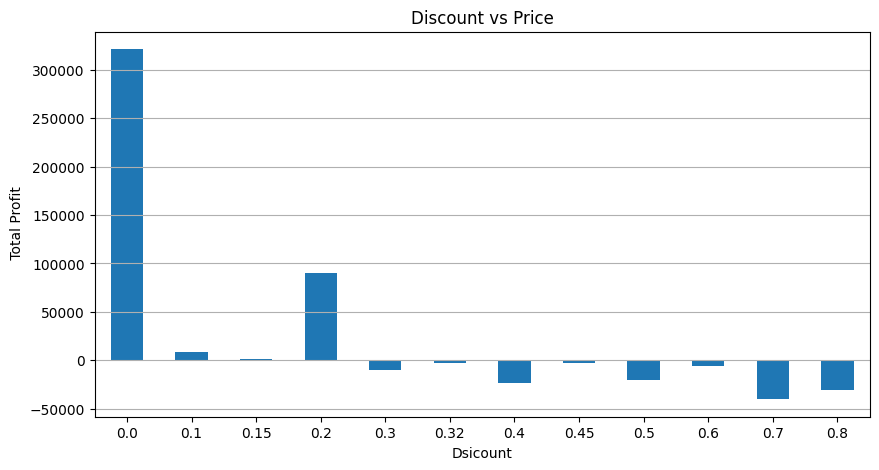

In [25]:
discount_profit.plot(kind="bar", figsize=(10,5))
plt.title("Discount vs Price")
plt.xlabel("Dsicount")
plt.ylabel(" Total Profit")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# Best performing category

In [26]:
best_category = df.groupby("Category")["Sales"].sum().idxmax()
print("Highest Performing Category: ",best_category)


Highest Performing Category:  Technology


# Best performing Region

In [27]:
best_region = df.groupby("Region")["Sales"].sum().idxmax()
print("Best performing region: ", best_region)

Best performing region:  West


# Best selling product

In [28]:
best_product = df.groupby("Product Name")["Sales"].sum().idxmax()
print("Best selling product: ",best_product)

Best selling product:  Canon imageCLASS 2200 Advanced Copier


# Overall Business Summary

In [29]:
summary = {
    "Total Sales": df["Sales"].sum(),
    "Total Profit": df["Profit"].sum(),
    "Total Quantity": df["Quantity"].sum(),
    "Total Orders": df["Order ID"].nunique(),
    "Total Customers": df["Customer ID"].nunique()
}
print("================ BUSINESS PERFORMANCE ================")
for key, value in summary.items():
    print(key, ":", round(value, 2))
print("======================================================")

================ BUSINESS PERFORMANCE ================
Total Sales : 2297200.86
Total Profit : 286397.02
Total Quantity : 37873
Total Orders : 5009
Total Customers : 793
